# Signal Processing

This notebook prepares the ECG and PCG signals for the models. Following the proposal and the plan (Nov-Dec 2026), the cardiac cycles are segmented with the synchronous ECG, first the R peaks are detected in the ECG, and then the S1 and S2 sounds are looked for in a window after each R peak, as in [5] (Klum et al.).

The recordings, their quality scores and saturation, and the per-patient labels come from `Data_Preparation.ipynb`.

## Table of contents

1. [Setup](#1-setup)
2. [Data](#2-data)
3. [First look at the ECG](#3-first-look-at-the-ecg)

### 1. Setup
[[go back to the top]](#table-of-contents)

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Make the project root importable, wherever the notebook is
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import neurokit2 as nk

from src.multiscope import *

### 2. Data
[[go back to the top]](#table-of-contents)

The recording index (one row per recording, with the ECG and PCG paths, the quality scores and the saturation) and the per-patient table (quality per site and labels), both saved by `Data_Preparation.ipynb`.

In [2]:
recordings = pd.read_pickle(RECORDINGS_FILE)
patients = pd.read_csv(PATIENTS_FILE, index_col="patient")

print(f"Recordings: {len(recordings)} | patients: {recordings['patient'].nunique()} | in the patient table: {len(patients)}")
recordings[["patient", "site", "app", "sqa_ecg", "sqa_pcg", "sat_ecg"]].head()

Recordings: 1350 | patients: 289 | in the patient table: 289


,patient,site,app,sqa_ecg,sqa_pcg,sat_ecg
0,1,AV,rijuven,2.0,1.0,19.310569
1,1,MV,rijuven,3.0,3.0,0.000000
2,1,PV,rijuven,4.0,4.0,0.000000
3,1,TV,rijuven,4.0,3.0,0.000000
4,2,AV,rijuven,0.0,3.0,35.076423


### 3. First look at the ECG
[[go back to the top]](#table-of-contents)

Before detecting the R peaks, this plots the first 5 seconds of the ECG of four kinds of recordings, to see how the R peaks look in each case: a good new app ECG, a saturated new app ECG, a good Rijuven ECG and a low quality ECG. One recording of each kind is picked at random, with a fixed seed so that it is always the same.

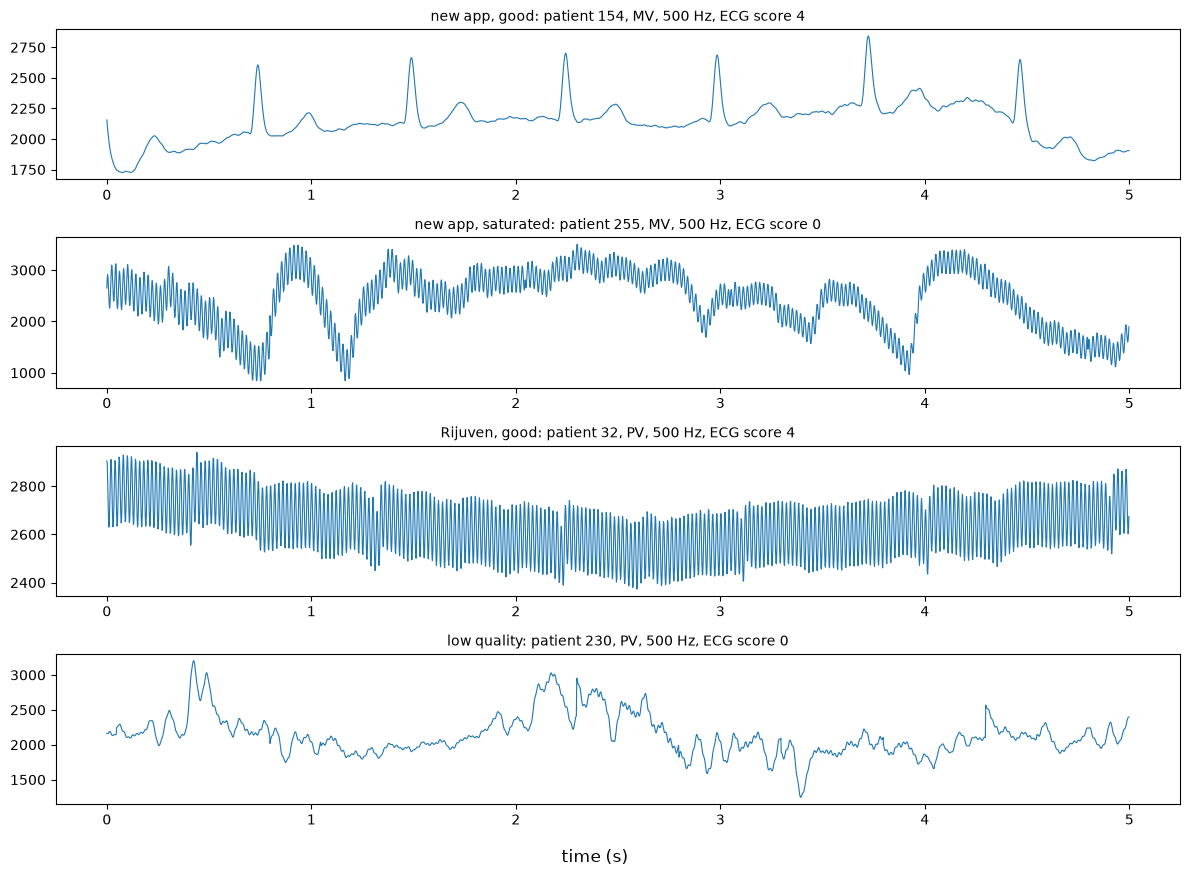

In [3]:
SECONDS = 5   # length of the plotted window

kinds = {
    "new app, good": recordings.query("app == 'new_app' and sqa_ecg >= 4 and sat_ecg == 0"),
    "new app, saturated": recordings.query("app == 'new_app' and sat_ecg > 5"),
    "Rijuven, good": recordings.query("app == 'rijuven' and sqa_ecg >= 4 and sat_ecg == 0"),
    "low quality": recordings.query("sqa_ecg == 0"),
}
examples = {kind: rows.sample(1, random_state=0).iloc[0] for kind, rows in kinds.items()}

fig, axes = plt.subplots(len(examples), 1, figsize=(12, 2.2 * len(examples)))
for ax, (kind, row) in zip(axes, examples.items()):
    ecg, _ = load_recording(row)
    window = ecg.data[:int(SECONDS * ecg.fs)]
    ax.plot(np.arange(len(window)) / ecg.fs, window, lw=0.8)
    ax.set_title(f"{kind}: patient {row['patient']}, {row['site']}, {ecg.fs:.0f} Hz, ECG score {row['sqa_ecg']:.0f}", fontsize=10)
fig.supxlabel("time (s)")
fig.tight_layout()